# AB-SAWの4分子・6分子閉路

Google Driveの既存試料を読み、C₄・C₆の全体、最大成分内、最大成分外の個数を集計します。分子列が同じ閉路は回転・逆向きを同一とし、同じ分子ペアの並列結合を1本にまとめます。

**初回は下のセルを上から実行し、Driveへのアクセスを許可してください。** 初期設定の `smoke` は保存済み1試料を読みます。成功すると `L128_phi0.10_i000000` の全体で C₄=6、C₆=0 になることを表示します。

| MODE | 対象 |
|---|---|
| `smoke` | 実試料1件。入出力と集計の確認 |
| `plan` | 条件と件数を検査。元の結合ファイルを開かない |
| `pilot` | L=32,64,128、目標占有率0.10〜0.70を0.01刻み、各条件1試料 |
| `full` | 同じ183条件で各100試料、合計18,300試料 |

`pilot` と `full` は同一出力先を使用し、入力・コードが一致する計算済み試料を再利用します。同じ出力先で同時に実行する場合は、先の実行が終了するのを待ってください。実験は占有率ごとに独立生成した保存済み試料を使用します。


In [3]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

MODE = "full"  # smoke / plan / pilot / full
DRIVE_ROOT = Path("/content/drive/MyDrive/tetra-peg-network")
STUDY = DRIVE_ROOT / "backup" / "h2_relation_fine_compact"
ARCHIVE = DRIVE_ROOT / "backup" / "h2_archive_20261028"
SAMPLES = STUDY / "results_fe428bde2d" / "samples.csv"
OUTPUT_ROOT = DRIVE_ROOT / "cycle46_report" / "all_occupancies"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


GitHub commit: 8137cd3c19cabd994964f8f03fbff14c09f21b8d
1/18300 new samples
100/18300 new samples
200/18300 new samples
300/18300 new samples
400/18300 new samples
500/18300 new samples
600/18300 new samples
700/18300 new samples
800/18300 new samples
900/18300 new samples
1000/18300 new samples
1100/18300 new samples
1200/18300 new samples
1300/18300 new samples
1400/18300 new samples
1500/18300 new samples
1600/18300 new samples
1700/18300 new samples
1800/18300 new samples
1900/18300 new samples
2000/18300 new samples
2100/18300 new samples
2200/18300 new samples
2300/18300 new samples
2400/18300 new samples
2500/18300 new samples
2600/18300 new samples
2700/18300 new samples
2800/18300 new samples
2900/18300 new samples
3000/18300 new samples
3100/18300 new samples
3200/18300 new samples
3300/18300 new samples
3400/18300 new samples
3500/18300 new samples
3600/18300 new samples
3700/18300 new samples
3800/18300 new samples
3900/18300 new samples
4000/18300 new samples
4100/18300 ne

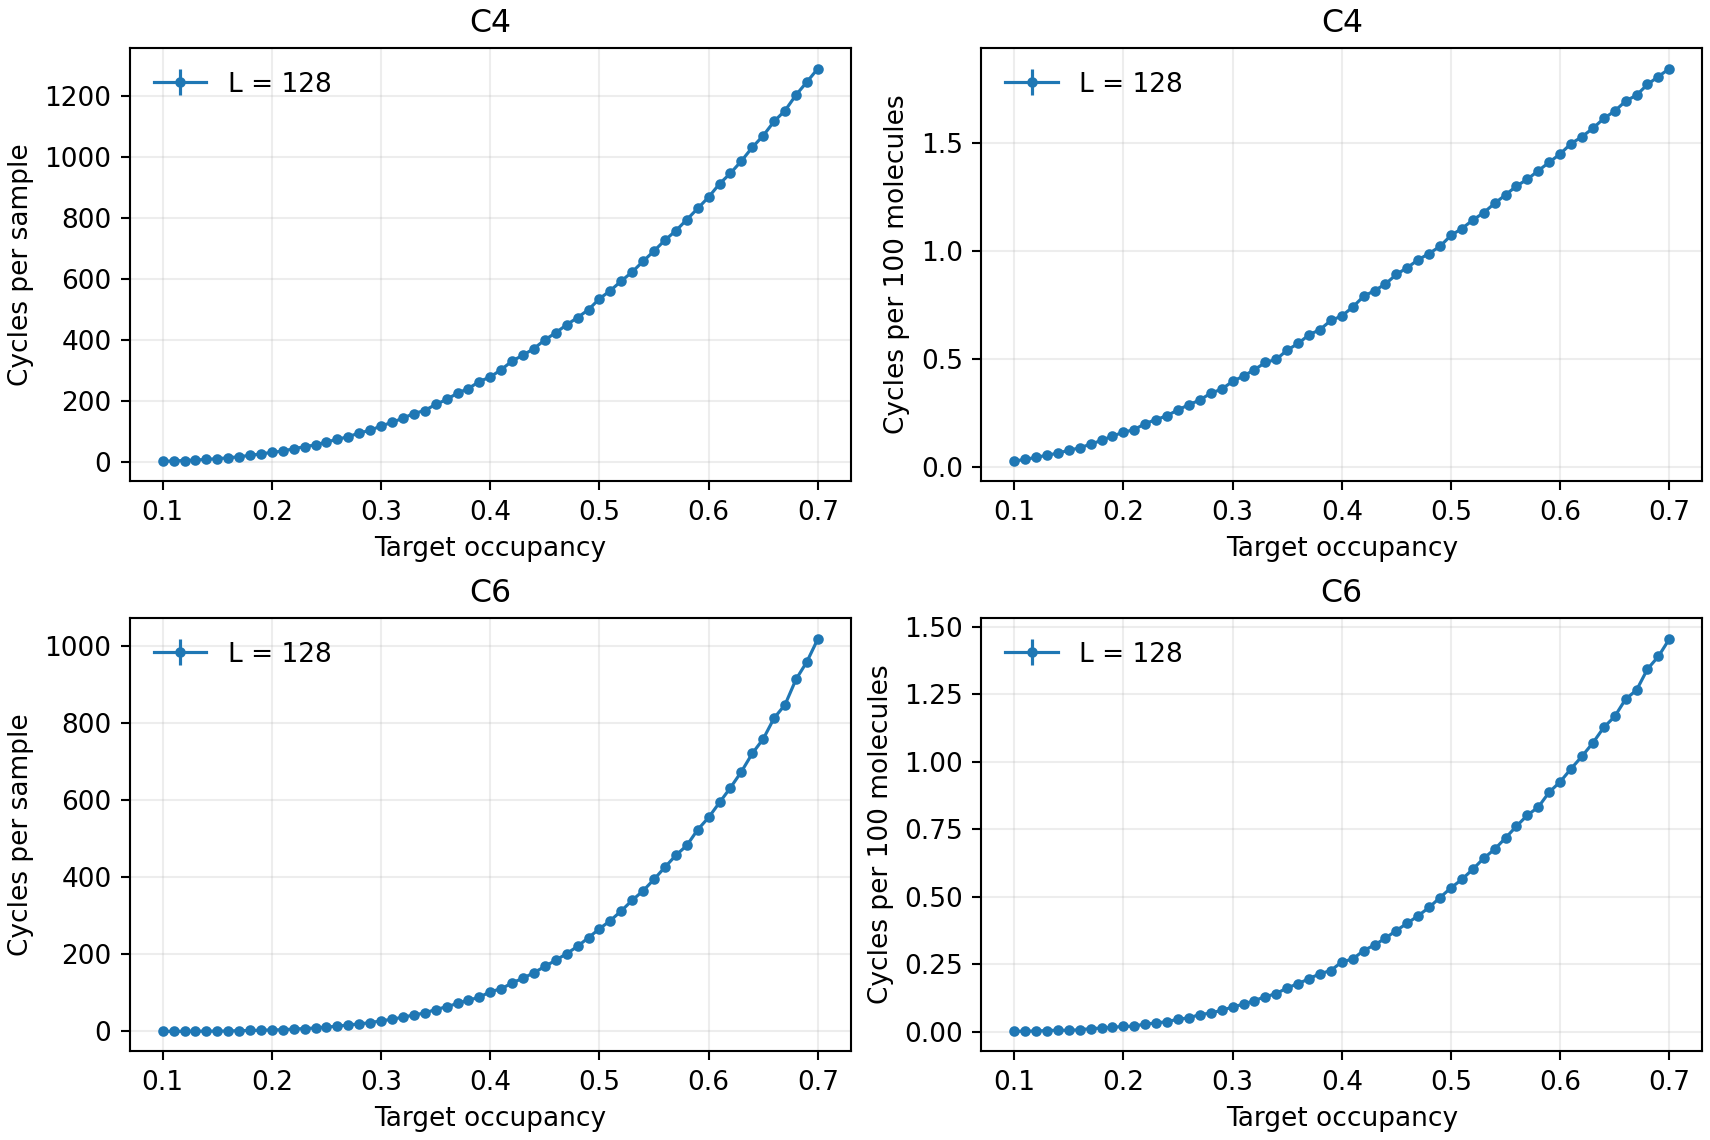

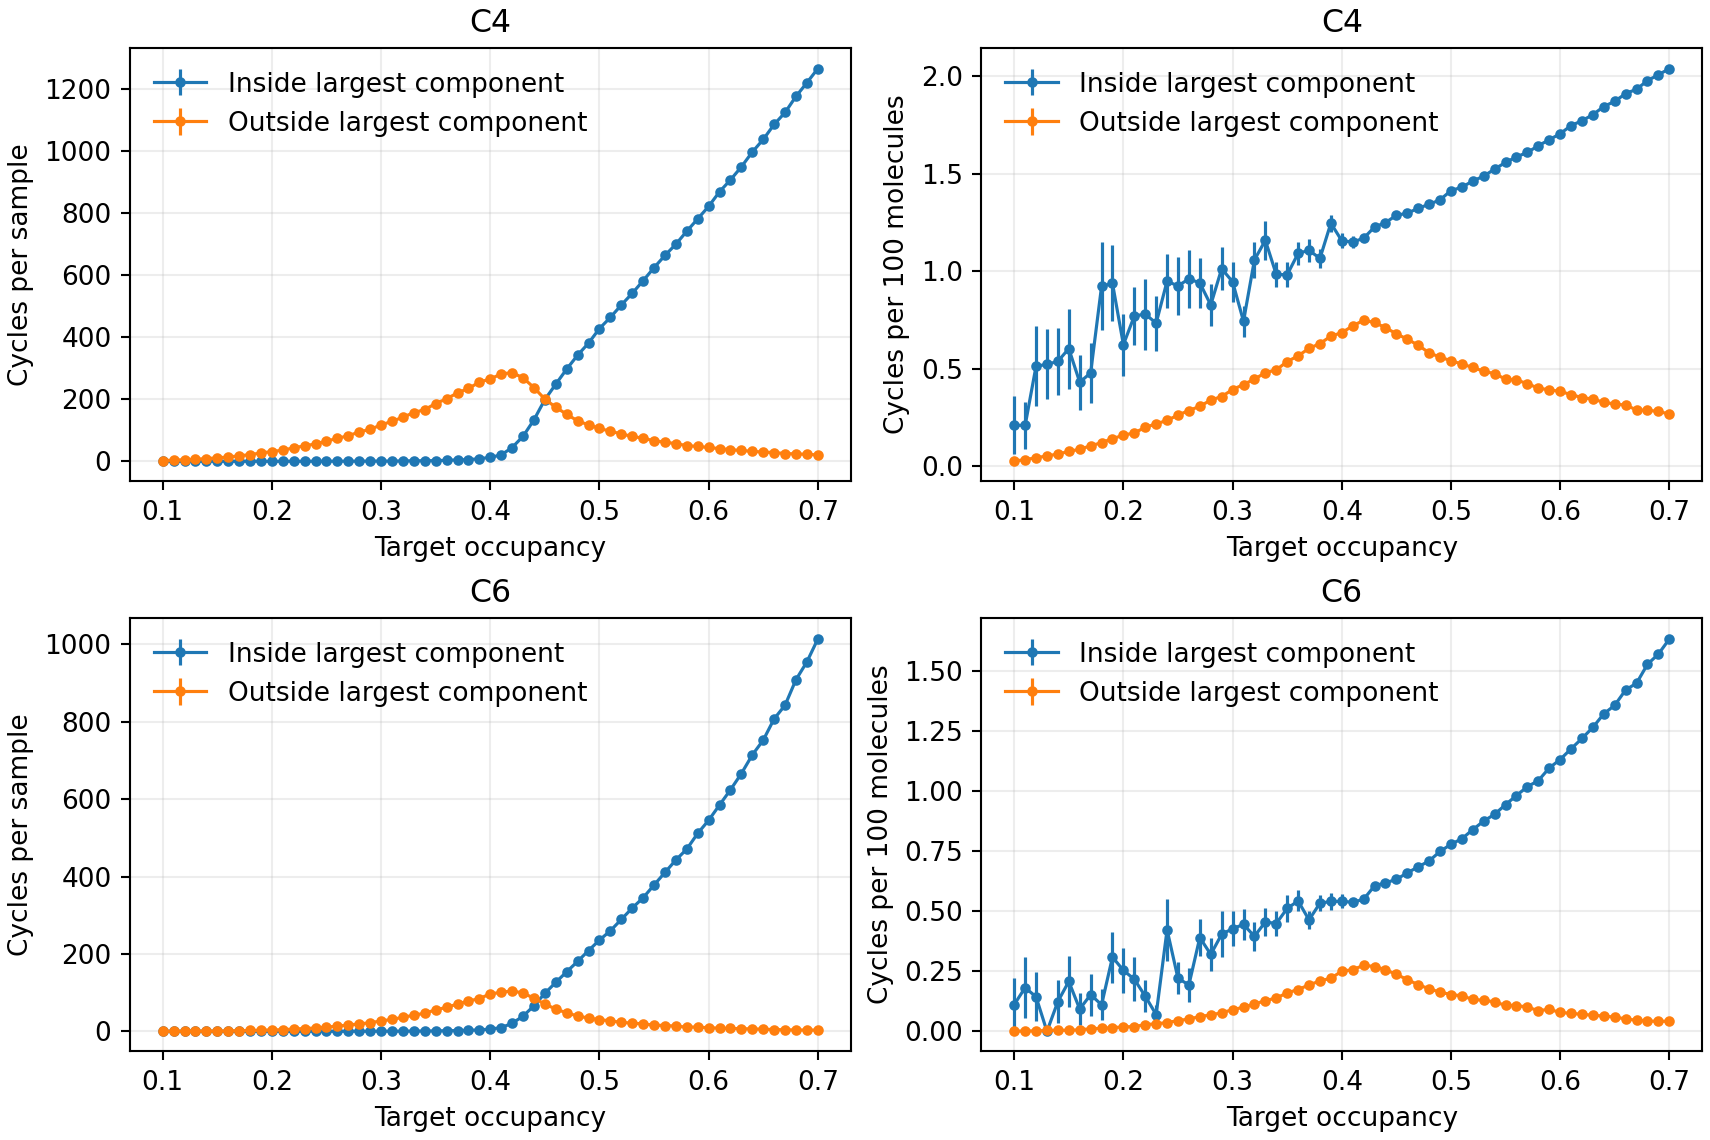

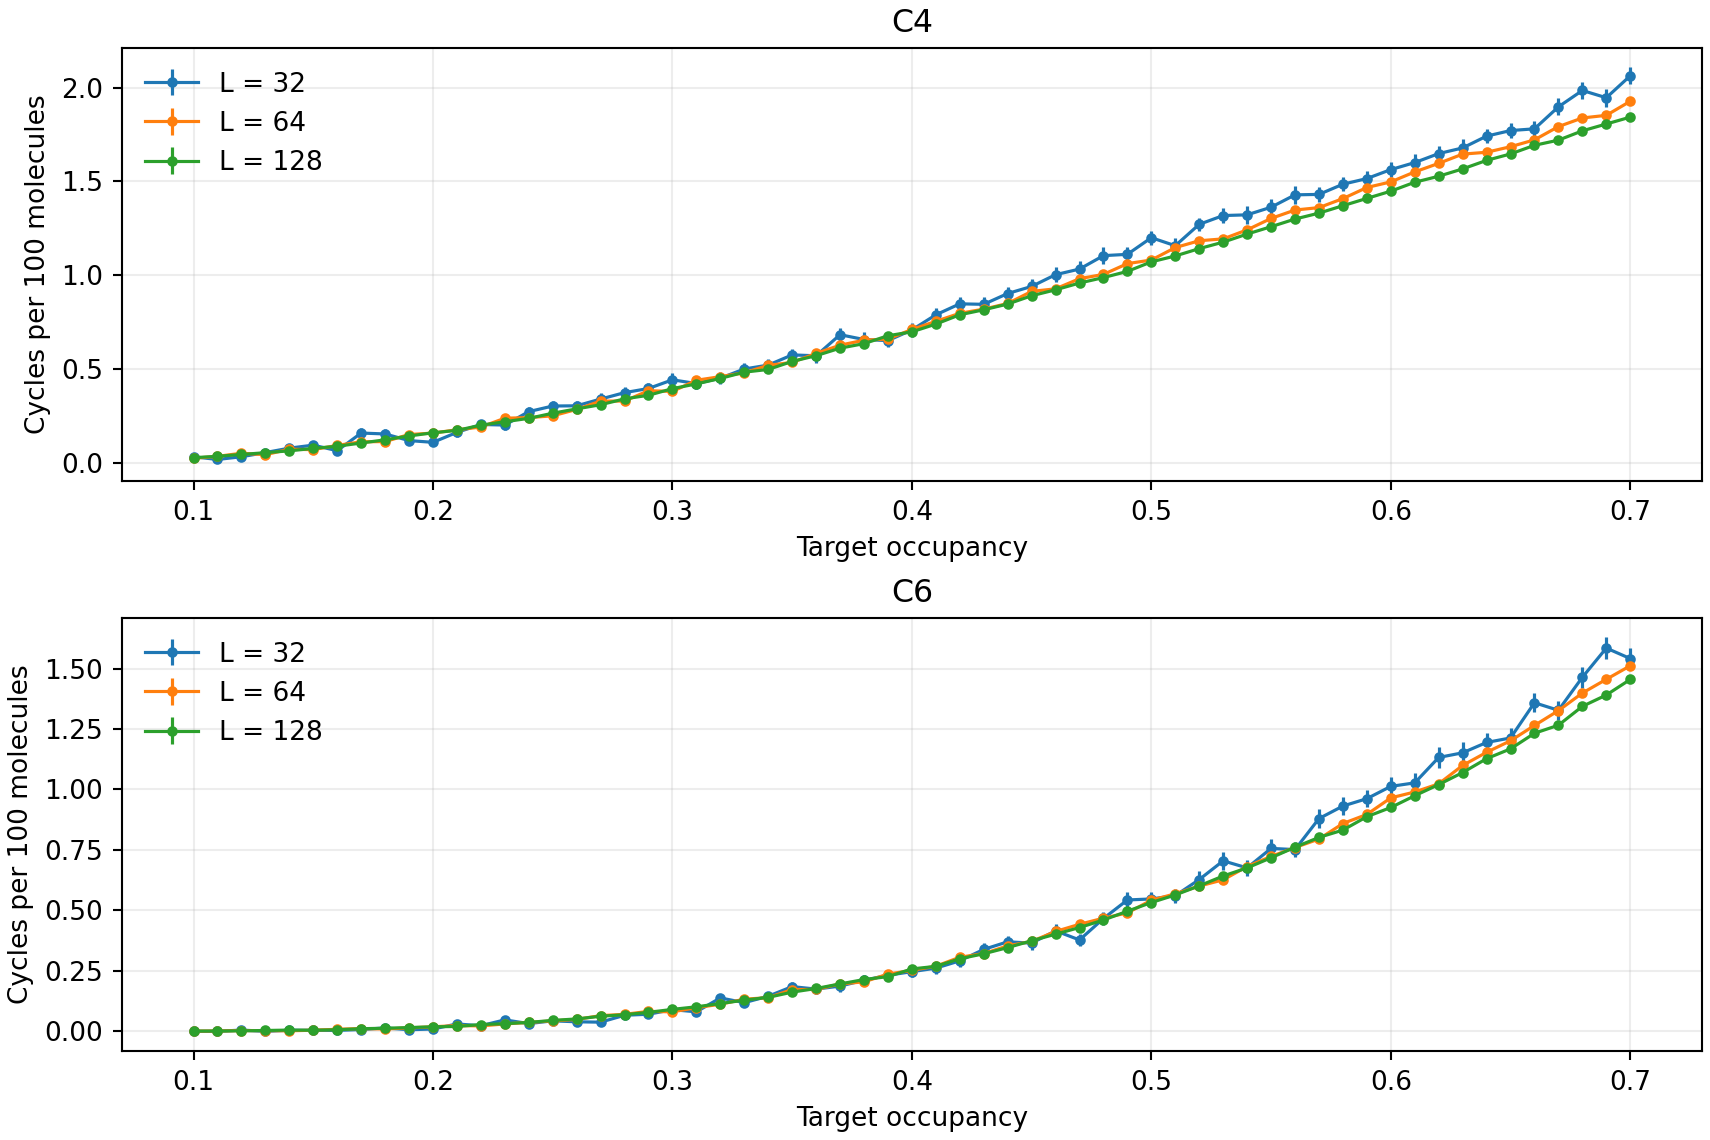

出力先 /content/drive/MyDrive/tetra-peg-network/cycle46_report/all_occupancies/comparison


In [4]:
import csv
from pathlib import Path
import subprocess
import sys
import tempfile
from IPython.display import Image, display

if MODE not in {"smoke", "plan", "pilot", "full"}:
    raise ValueError("MODE は smoke / plan / pilot / full から選んでください。")

sample_candidates = [SAMPLES, SAMPLES.with_name("upload_h2_validation.zip")]
samples = next((path for path in sample_candidates if path.is_file()), None)
if samples is None:
    raise FileNotFoundError(f"試料表がありません。SAMPLES を samples.csv または保存済みZIPに設定してください。確認先 {SAMPLES}")

case = "L128_phi0.10_i000000"
quick_run = STUDY / "cases" / case / "runs" / case
has_loose_case = all(
    (quick_run / name).is_file() or (quick_run / (name + ".gz")).is_file()
    for name in ("bonds.csv", "cluster-members.csv")
)
if MODE == "smoke" and has_loose_case:
    source = ["--study", str(STUDY)]
elif (ARCHIVE / "h2.tar.part-000").is_file() or MODE == "plan":
    source = ["--archive", str(ARCHIVE)]
    if MODE == "smoke":
        print("分割バックアップで対象試料まで順に読みます。")
else:
    source = ["--study", str(STUDY)]

branch = "codex/ab-saw-cycle46-colab"
with tempfile.TemporaryDirectory(prefix="cycle46_repo_") as temp:
    repo = Path(temp) / "tetra-peg-network"
    subprocess.run([
        "git", "clone", "--quiet", "--depth", "1", "--branch", branch,
        "https://github.com/takakei510/tetra-peg-network.git", str(repo),
    ], check=True)
    commit = subprocess.check_output(["git", "-C", str(repo), "rev-parse", "HEAD"], text=True).strip()
    print(f"GitHub commit: {commit}", flush=True)
    output = OUTPUT_ROOT / ("smoke" if MODE == "smoke" else "comparison")
    cmd = [
        sys.executable, str(repo / "scripts" / "analysis" / "compare_cycles_46.py"),
        "--repo", str(repo), "--samples", str(samples), *source,
        "--output", str(output), "--phis", "all",
    ]
    if MODE == "plan":
        cmd += ["--plan"]
    elif MODE == "smoke":
        cmd += ["--replicates", "1", "--case", case]
    elif MODE == "pilot":
        cmd += ["--replicates", "1"]
    process = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        if process.wait() != 0:
            raise subprocess.CalledProcessError(process.returncode, cmd)
    finally:
        if process.poll() is None:
            process.terminate()
            process.wait()

if MODE == "smoke":
    with (output / "cycle46_samples.csv").open(encoding="utf-8-sig", newline="") as handle:
        row = next(csv.DictReader(handle))
    actual = (int(row["C4_mol"]), int(row["C6_mol"]))
    if row["case_id"] != case or actual != (6, 0):
        raise ValueError(f"保存済み試料の参照値と一致しません。{row['case_id']} C4,C6 = {actual}")
    print(f"{case}: C4={actual[0]}, C6={actual[1]}。参照値と一致しました。")
elif MODE in {"pilot", "full"}:
    for name in ("01_occupancy.png", "02_largest_component.png", "03_lattice_size.png"):
        display(Image(filename=str(output / name)))

if MODE != "plan":
    print(f"出力先 {output}")


```markdown
# 📄 発表スライド構成案：AB-SAWの4分子・6分子閉路分析
---
## 1. 研究の背景と目的

### 💡 背景：テトラPEGゲルなどの高分子ネットワーク
* 高分子同士がランダムに結合して構築される網目構造の評価が重要。
* ネットワーク形成時に、物理的な硬さに寄与しない**不完全な結合（無効ループ）**が発生する。

### 🎯 本分析の目的
* 高分子シミュレーションモデル（AB-SAW）から得られたデータを用いて、最小のループ構造である**4分子閉路 ($C_4$)** および **6分子閉路 ($C_6$)** の個数を精密に集計・評価する。
```

```markdown
## 2. 解析手法（トポロジー処理の工夫）

### 🔄 重複の厳密な排除
* 閉路（サイクル）を検出する際、以下のケースをすべて**同一の閉路**として重複排除を行う：
  * **回転対称（分子の並び順の開始点のズレ）**
  * **反転（逆向きの探索）**

### 🔗 並列結合の簡約化
* 同じ分子ペアが複数箇所で二重に繋がっている「並列結合」は、トポロジー上**1本**としてまとめて処理を行うことで、正確な輪の数を測定する。
```

```markdown
## 3. シミュレーション環境とデータスケール

### ⚙️ 実行モードの設計
1. **`smoke`（動作確認）** : 保存済み代表試料1件を用いたテスト実行。
2. **`plan`（検証）** : 各条件のデータ件数・構成をチェック。
3. **`pilot`（小規模試験）** : 境界効果や初期値の影響を素早く確認（L=32,64,128、目標占有率 $\phi=0.10 \sim 0.70$ 各1試料）。
4. **`full`（本実行）** : 183条件 $\times$ 各100試料（計 18,300 試料）のビッグデータ解析。
```

```markdown
## 4. 分析結果（検証データ：L128_phi0.10_i000000）

### 📊 検出されたループ数
* **4分子閉路 ($C_4$)**:  **6個**
* **6分子閉路 ($C_6$)**:  **0個**

### 🔍 結論と今後の展望
* `smoke` 実行において、参照データ（基準値）と完全に一致することを確認（システム検証の成功）。
* 今後は `pilot` および `full` モードを回し、占有率 $\phi$（ポリマー濃度）やシステムサイズ $L$ の変化に対して、これらの欠陥ループ数がどのようにスケールしていくかをグラフ化し、ゲルの弾性率（物理的な硬さ）への影響を評価する。
```